# Gaussian process optimizer

Copyright (C) 2024 Hirokazu Maesaka, RIKEN SPring-8 Center. All rights reserved.

This program is free software: you can redistribute it and/or modify it under the terms of the GNU General Public License as published by the Free Software Foundation, either version 3 of the License, or (at your option) any later version.

This program is distributed in the hope that it will be useful, but WITHOUT ANY WARRANTY; without even the implied warranty of MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU General Public License for more details.

You should have received a copy of the GNU General Public License along with this program. If not, see <https://www.gnu.org/licenses/>.

In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# Parameters
plt.rcParams['font.size'] = 16
sigma_0 = 2.0
sigma_e = 0.5
xmin = 0.
xmax = 10.
nx = 201
x = np.linspace(xmin, xmax, nx)

## Function definition
- True function: $y = x \sin{x}$

In [3]:
# True function and data taking function
def true_func(x):
    return x * np.sin(x)

def take_data(x):
    return true_func(x) + np.random.randn()*sigma_e

## Gaussian process regression

In [4]:
# Gaussian process regression
def gpr(x, xd, yd, err, sig0):
    dx = np.vstack([xd]*len(xd)) - np.vstack([xd]*len(xd)).T
    Sigma = sig0**2 * np.exp(-0.5*dx**2)
    Sigma += np.eye(len(xd))*err**2
    dx = np.vstack([x]*len(xd)) - np.vstack([xd]*len(x)).T
    kd = sig0**2 * np.exp(-0.5*dx**2)
    dx = np.vstack([x]*len(x)) - np.vstack([x]*len(x)).T
    k = sig0**2 * np.exp(-0.5*dx**2)
    mean = kd.T @ np.linalg.inv(Sigma) @ yd.T
    var = k - kd.T @ np.linalg.inv(Sigma) @ kd
    return mean, var

## Expected improvement (EI)
$$
\alpha_\mathrm{EI}(x) = \int_{y_\mathrm{max}}^\infty{(y-y_\mathrm{max})\, p(y|y_\mathcal{D},\mathrm{X}_\mathcal{D},x)\, dy}
= (\mu(x) - y_\mathrm{max}) \Phi(t) + \sigma(x) \phi(t)
$$
- $t = \frac{\mu(x) - y_\mathrm{max}}{\sigma(x)}$
- $\Phi(t)$: cumulative distribution function of a normal distribution
- $\phi(t)$: probability density function of a normal distribution

In [5]:
# Expected improvement
def EI(yd, mu, v):
    ymax = np.max(yd)
    sig = np.sqrt(np.diagonal(v))
    t = (mu - ymax) / sig
    return (mu - ymax) * scipy.stats.norm.cdf(t) + sig * scipy.stats.norm.pdf(t)

## Upper confidence bound (UCB)
$$
\alpha_\mathrm{UCB} = \mu(x) + \lambda\sigma(x)
$$

In [6]:
# Upper confidence bound
def UCB(mu, v, a=1.96):
    sig = np.sqrt(np.diagonal(v))
    return mu + a*sig

## Take first data before optimization

In [7]:
# take first data
x_d = np.array([x[nx//2]])
y_d = np.array([take_data(x_d[0])])

## Plot with EI

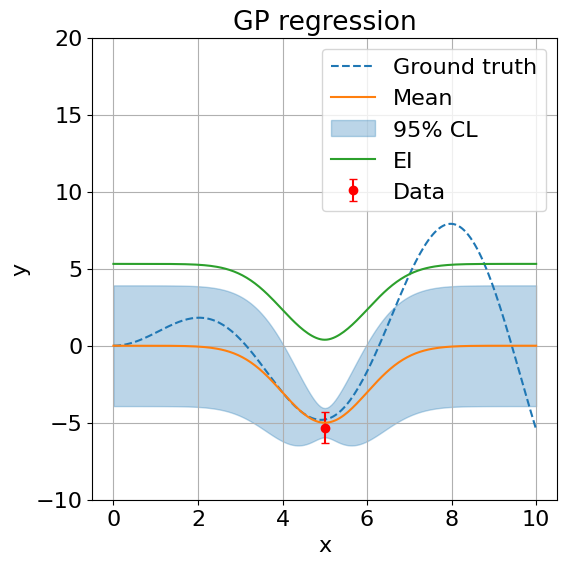

In [8]:
# GP with EI
mean, var = gpr(x, x_d, y_d, sigma_e, sigma_0)
sigma = np.sqrt(var.diagonal())

fig, ax = plt.subplots(figsize=(6,6))
ax.plot(x, true_func(x), '--', color='C0', label='Ground truth')
ax.errorbar(x_d, y_d, sigma_e*1.96, fmt='ro', capsize=3, label='Data')
ax.plot(x, mean, color='C1', label='Mean')
ax.fill_between(x, mean-sigma*1.96, mean+sigma*1.96, color='C0', alpha=0.3, label=r'95% CL')
ax.plot(x, EI(y_d,mean,var), color='C2', label='EI')
ax.legend()
ax.grid()
ax.set_ylim([-10,20])
ax.set_title(f'GP regression')
ax.set_xlabel('x')
ax.set_ylabel('y')
plt.show()

## Plot with UCB

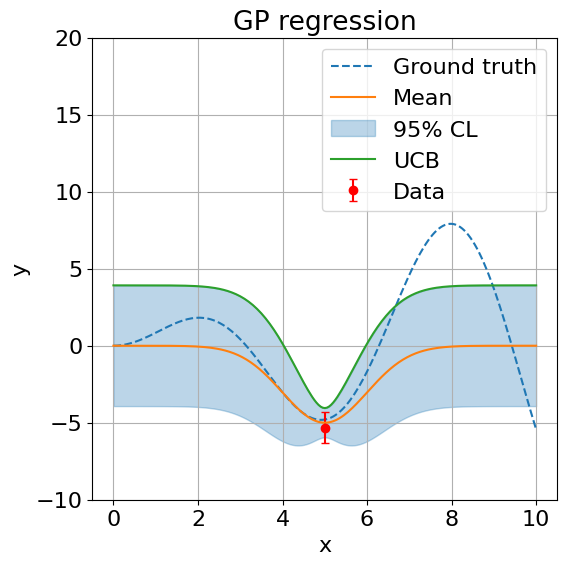

In [9]:
# GP with UCB
mean, var = gpr(x, x_d, y_d, sigma_e, sigma_0)
sigma = np.sqrt(var.diagonal())

fig, ax = plt.subplots(figsize=(6,6))
ax.plot(x, true_func(x), '--', color='C0', label='Ground truth')
ax.errorbar(x_d, y_d, sigma_e*1.96, fmt='ro', capsize=3, label='Data')
ax.plot(x, mean, color='C1', label='Mean')
ax.fill_between(x, mean-sigma*1.96, mean+sigma*1.96, color='C0', alpha=0.3, label=r'95% CL')
ax.plot(x, UCB(mean,var), color='C2', label='UCB')
ax.legend()
ax.grid()
ax.set_ylim([-10,20])
ax.set_title(f'GP regression')
ax.set_xlabel('x')
ax.set_ylabel('y')
plt.show()

## Optimization with EI

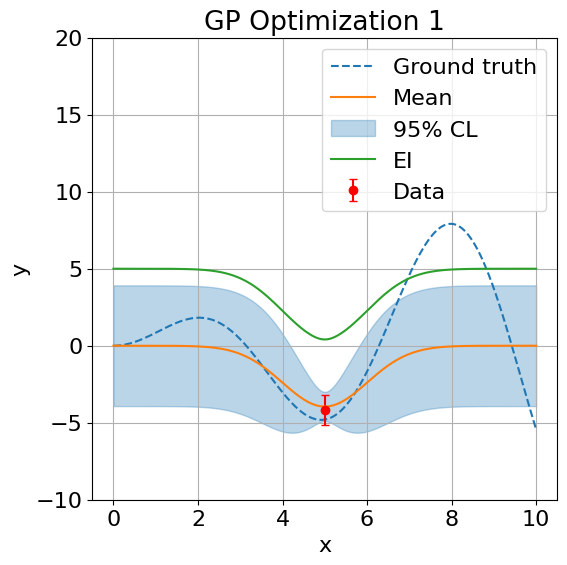

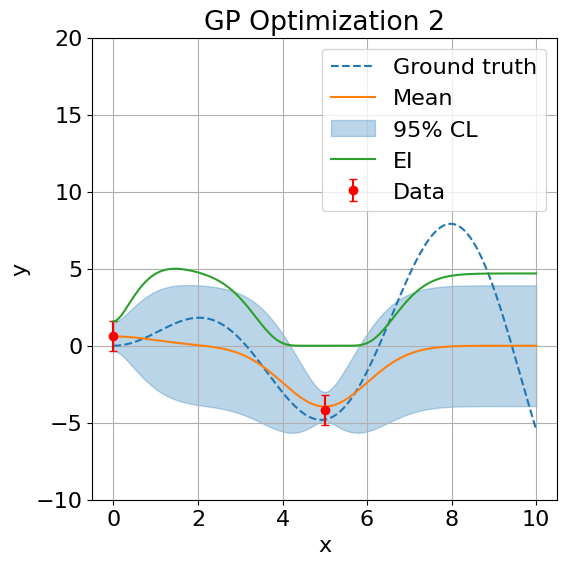

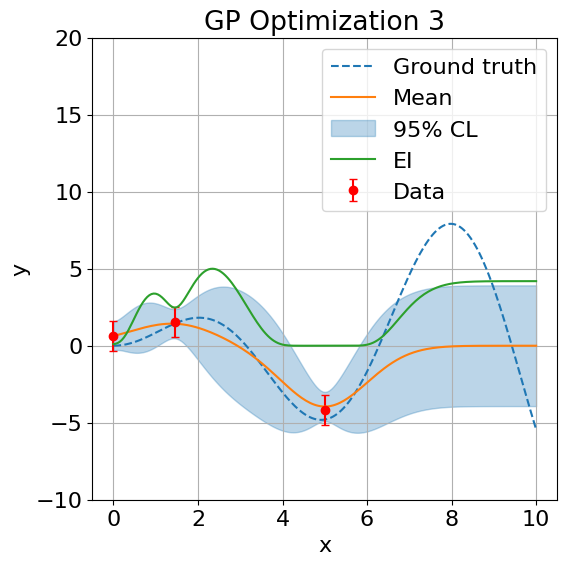

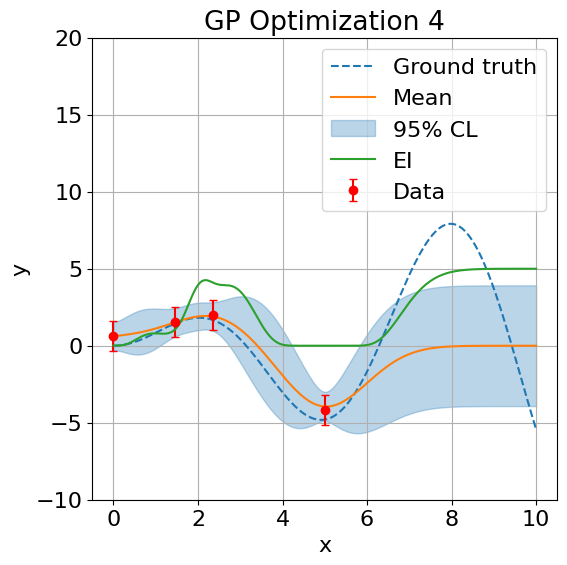

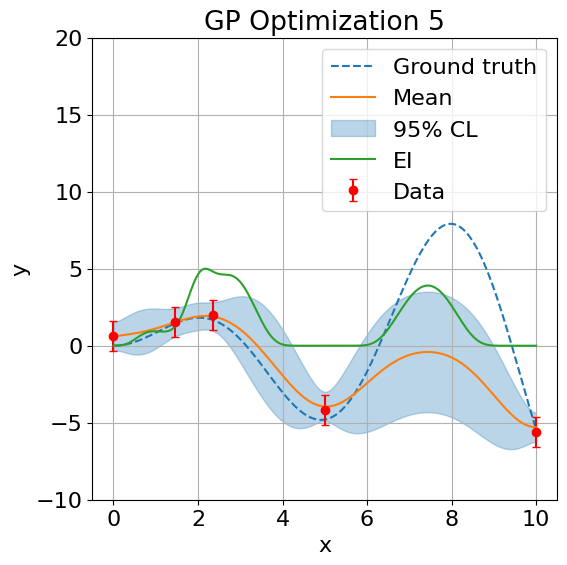

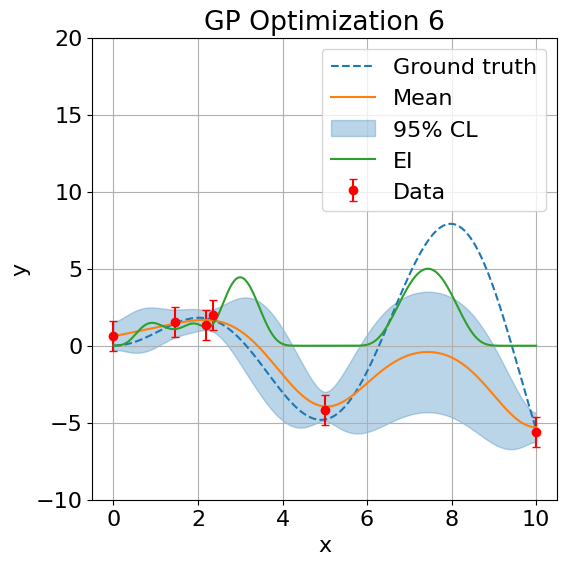

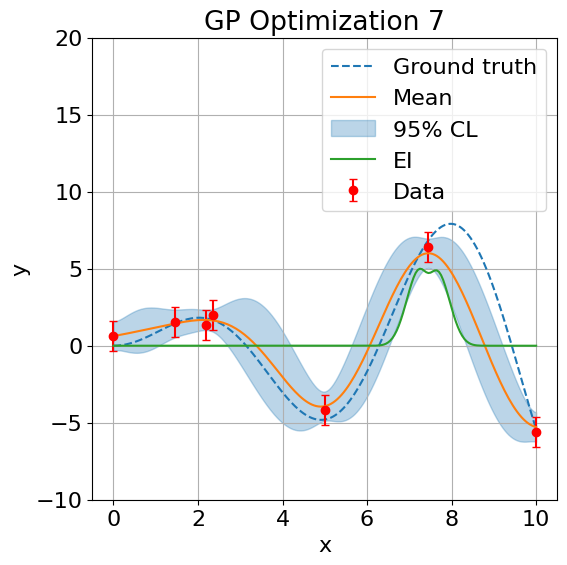

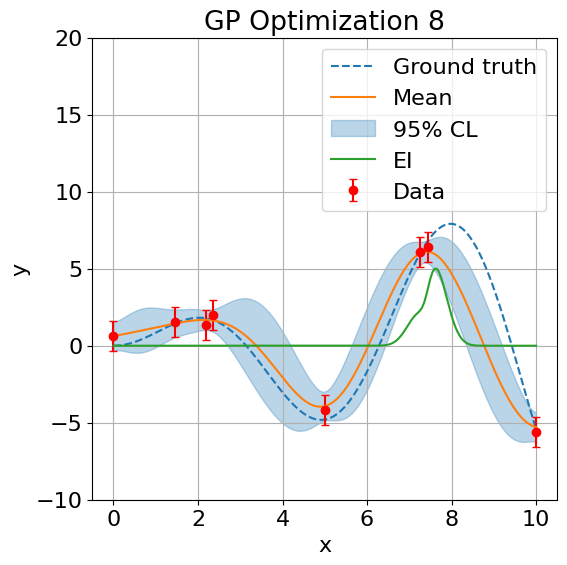

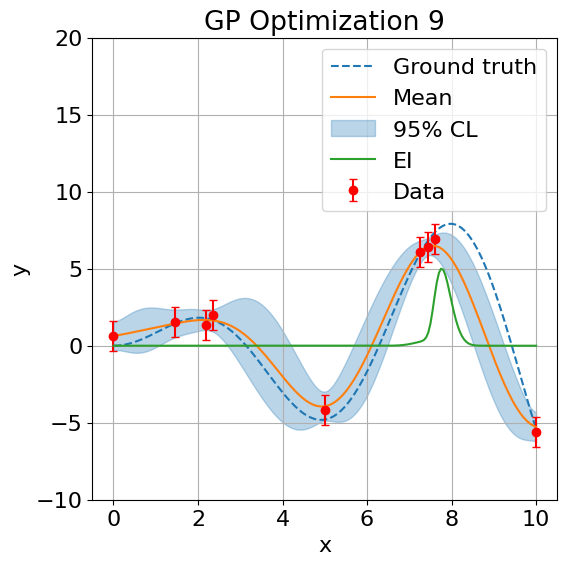

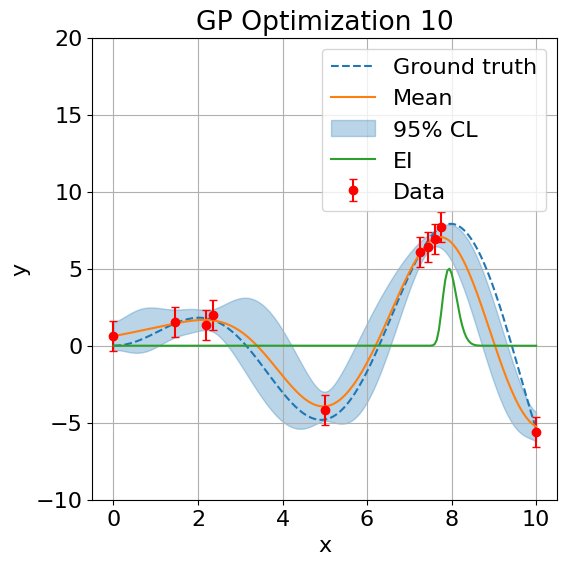

In [10]:
# Optimization with EI
niter = 10

x_d = np.array([x[nx//2]])
y_d = np.array([take_data(x_d[0])])

for i in range(niter):
    mean, var = gpr(x, x_d, y_d, sigma_e, sigma_0)
    sigma = np.sqrt(var.diagonal())
    ei = EI(y_d,mean,var)
    fig, ax = plt.subplots(figsize=(6,6))
    ax.plot(x, true_func(x), '--', color='C0', label='Ground truth')
    ax.errorbar(x_d, y_d, sigma_e*1.96, fmt='ro', capsize=3, label='Data')
    ax.plot(x, mean, color='C1', label='Mean')
    ax.fill_between(x, mean-sigma*1.96, mean+sigma*1.96, color='C0', alpha=0.3, label=r'95% CL')
    ax.plot(x, ei/np.max(ei)*5., color='C2', label='EI')
    ax.legend()
    ax.grid()
    ax.set_ylim([-10,20])
    ax.set_title(f'GP Optimization {i+1}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    plt.show()
    x_d = np.append(x_d, x[np.argmax(ei)])
    y_d = np.append(y_d, take_data(x_d[-1]))

## Optimization with UCB

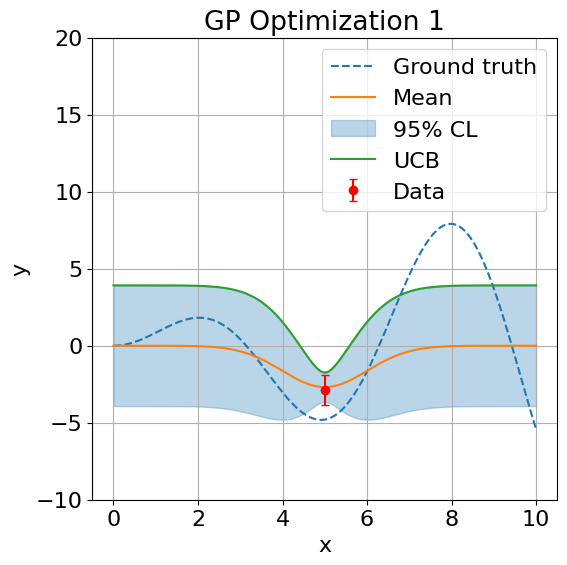

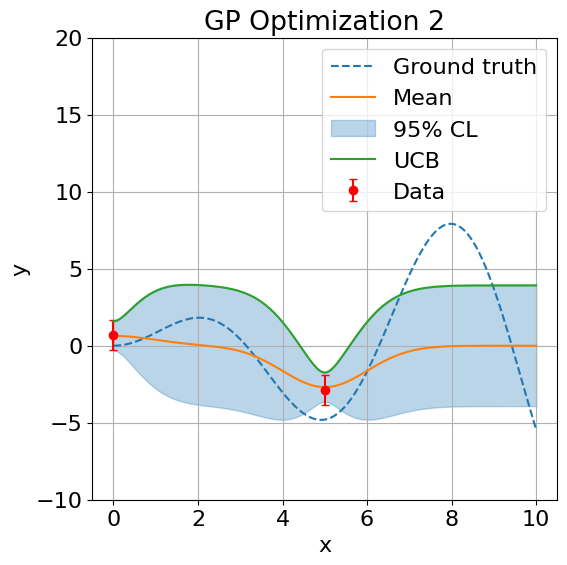

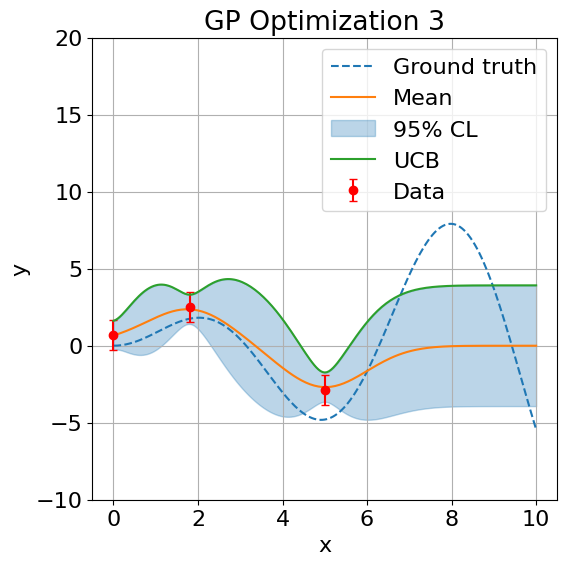

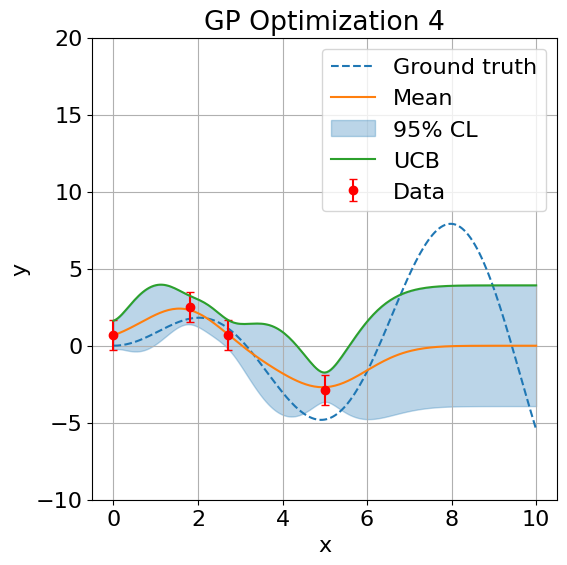

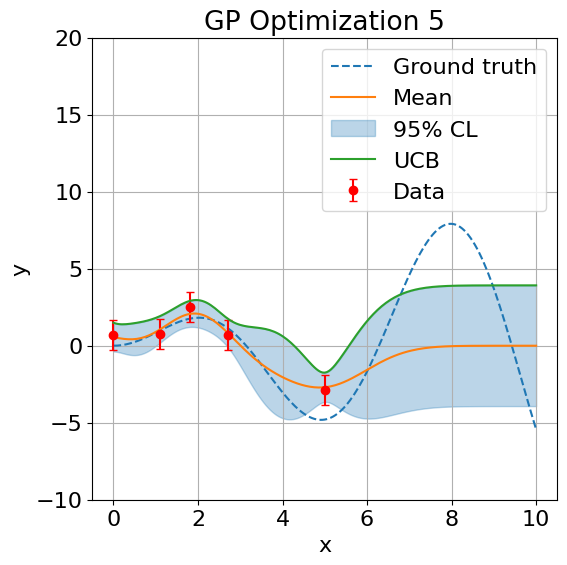

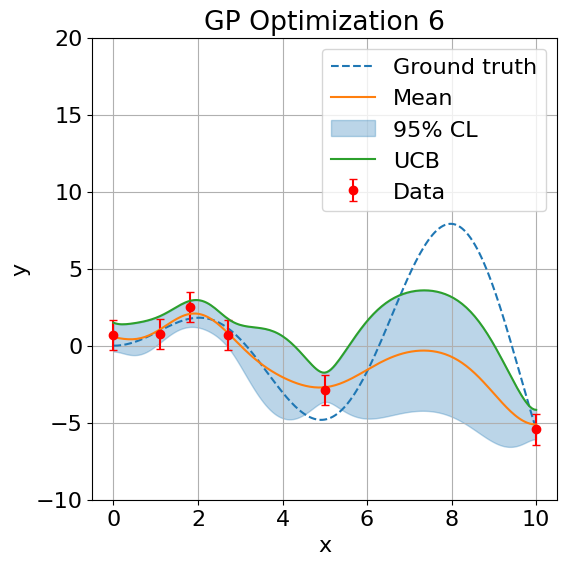

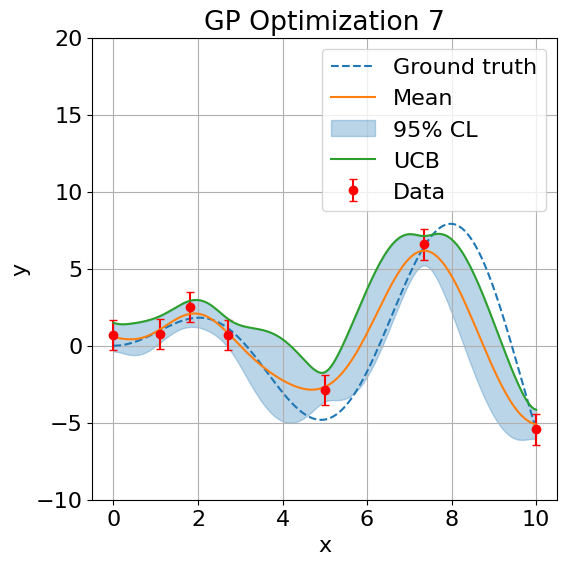

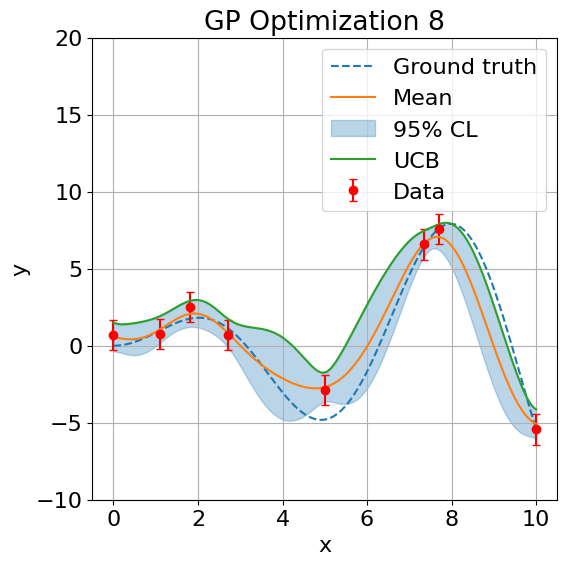

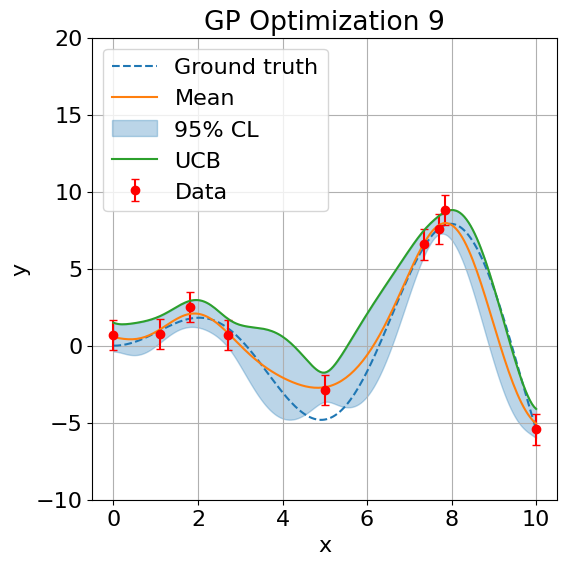

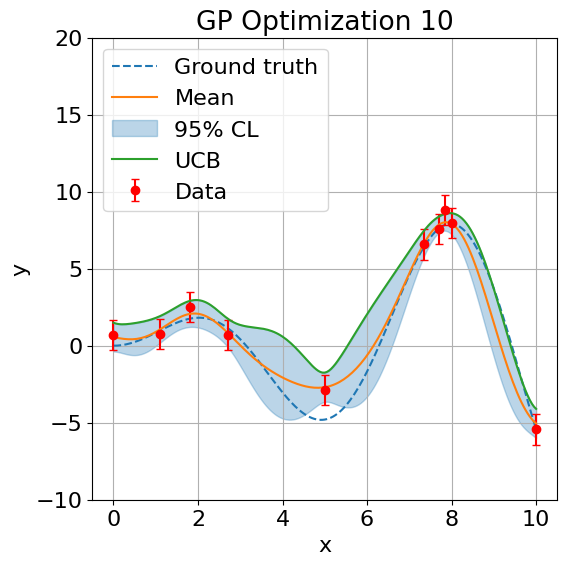

In [11]:
# Optimization with UCB
niter = 10

x_d = np.array([x[nx//2]])
y_d = np.array([take_data(x_d[0])])

for i in range(niter):
    mean, var = gpr(x, x_d, y_d, sigma_e, sigma_0)
    sigma = np.sqrt(var.diagonal())
    ucb = UCB(mean,var)
    fig, ax = plt.subplots(figsize=(6,6))
    ax.plot(x, true_func(x), '--', color='C0', label='Ground truth')
    ax.errorbar(x_d, y_d, sigma_e*1.96, fmt='ro', capsize=3, label='Data')
    ax.plot(x, mean, color='C1', label='Mean')
    ax.fill_between(x, mean-sigma*1.96, mean+sigma*1.96, color='C0', alpha=0.3, label=r'95% CL')
    ax.plot(x, ucb, color='C2', label='UCB')
    ax.legend()
    ax.grid()
    ax.set_ylim([-10,20])
    ax.set_title(f'GP Optimization {i+1}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    plt.show()
    x_d = np.append(x_d, x[np.argmax(ucb)])
    y_d = np.append(y_d, take_data(x_d[-1]))